# Notebook 1 — mmWave Radar Simulation

**CSCI 4900/6900 · Simulation lesson · English · No radar hardware required**

Use known targets to learn how **Range Spectrum → Doppler Spectrum → Angular Spectrum**
answer three questions: how far, how fast along the line of sight, and in which direction?
All signals in this notebook are **simulated**. The measured-data lesson is in
[Notebook 2 — Real Radar Data](lab7_mmwave_real_data.ipynb).

This notebook is standalone: run it in a fresh kernel. It generates its own data and does not
load the measured-data subset or depend on variables from another notebook.
Install the dependencies using the [README instructions](README.md) **before class**. Use your existing Python installation; a dedicated virtual environment is optional.

**Class route:** run Sections 1–4, then stop at **Core checkpoint** and switch to Notebook 2.
Appendices are optional after-class material; no core cell depends on them.
Saved outputs are included for preview. During class, predict → run → interpret; parameter sweeps are optional.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Support launching from the lab directory or repository root.
LAB = Path.cwd()
if not (LAB / "lab7_mmwave_simulation.ipynb").exists():
    LAB = LAB / "Lab-7-mmWave"
if not (LAB / "lab7_mmwave_simulation.ipynb").exists():
    raise FileNotFoundError("Start Jupyter from Lab-7-mmWave or the repository root.")
FIG = LAB / "figures" / "simulation"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.figsize": (10, 3.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "font.size": 10,
})
C = 299_792_458.0

def db_power(power, reference=None, floor=-60):
    # Input power |X|^2; use 10 log10. The specified reference is 0 dB, not dBm.
    power = np.asarray(power, dtype=float)
    if reference is None:
        reference = float(np.max(power))
    reference = max(float(reference), np.finfo(float).tiny)
    return 10 * np.log10(np.maximum(power / reference, 10.0**(floor / 10)))

def finish(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()

print("NumPy:", np.__version__)
print("Environment ready; simulated data will be generated locally. No measured-data files are required.")

NumPy: 2.5.4
Environment ready; simulated data will be generated locally. No measured-data files are required.


## 1. I/Q and the data cube

FMCW stands for Frequency-Modulated Continuous Wave. The transmitted frequency sweeps during each chirp.
The returning echo has a round-trip delay $\tau=2R/c$. The receiver mixes the echo with a local reference to obtain a lower-frequency **beat / IF signal**.
The ADC samples this mixed signal; **it does not directly sample the 77 GHz waveform**.

We store the samples as complex values $x=I+jQ$. Amplitude describes reflection strength, while phase changes contain motion and direction information.
A stationary target can still produce a nonzero beat frequency. An oscillating signal alone does not imply a moving object.

The plots below illustrate the principle; they are not a complete timing diagram of the recorded hardware.
**Predict first:** a farther target has a longer delay. Should its beat frequency be higher or lower?

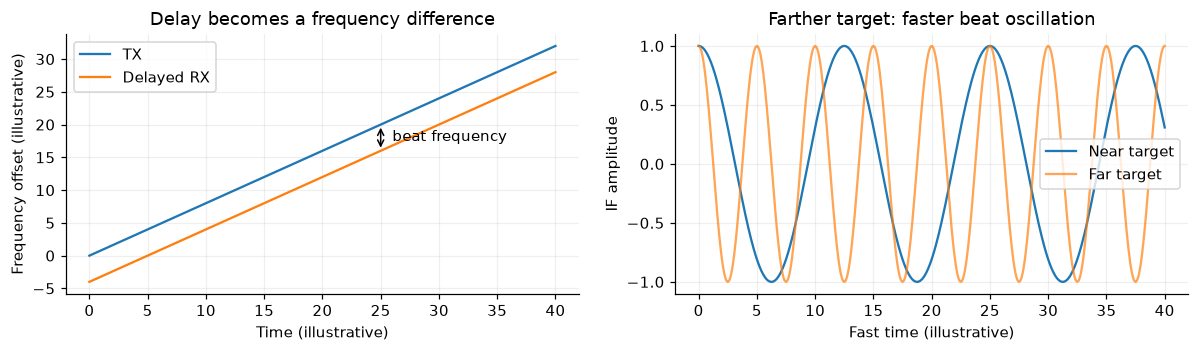

In [2]:
t_demo = np.linspace(0, 40, 500)
delay_demo = 5.0
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
axes[0].plot(t_demo, 0.8*t_demo, label="TX")
axes[0].plot(t_demo, 0.8*(t_demo-delay_demo), label="Delayed RX")
axes[0].annotate("", xy=(25, 20), xytext=(25, 16),
                 arrowprops={"arrowstyle": "<->"})
axes[0].text(26, 17.5, "beat frequency")
axes[0].set(xlabel="Time (illustrative)", ylabel="Frequency offset (illustrative)",
            title="Delay becomes a frequency difference")
axes[0].legend()
axes[1].plot(t_demo, np.cos(2*np.pi*0.08*t_demo), label="Near target")
axes[1].plot(t_demo, np.cos(2*np.pi*0.20*t_demo), alpha=.7, label="Far target")
axes[1].set(xlabel="Fast time (illustrative)", ylabel="IF amplitude",
            title="Farther target: faster beat oscillation")
axes[1].legend()
finish("00_chirp_and_beat")

### 1.1 One data cube, three sampling axes

Throughout this simulation, we use `adc[m, a, n]` with shape **[chirp, antenna, sample]**.

| Dimension | What stays fixed; what varies | Source of the phase progression | After transformation |
|---|---|---|---|
| `axis=2`: fast time | Fix a chirp and antenna; read ADC samples within that chirp | Echo delay creates a beat frequency | Range |
| `axis=0`: slow time | Fix a range bin and antenna; read successive chirps | Motion advances phase between chirps | Doppler / radial velocity |
| `axis=1`: space | Fix a range–Doppler bin; read multiple antennas | Arrival direction creates spatial phase differences | Angle / azimuth |

~~~text
adc [chirp, antenna, sample]       (complex)
                 │ Range FFT: axis=2
                 ▼
R   [chirp, antenna, range]        (complex)
                 │ Doppler FFT: axis=0
                 ▼
RD  [doppler, antenna, range]      (complex)
                 │ Select one (doppler, range) cell; keep the antenna axis
                 ▼
z   [antenna] → Angle FFT / beamforming → angular spectrum
~~~

**Key rule:** use `abs()` for amplitude or power displays, and preserve the complex arrays needed by later stages.
Taking the magnitude of the Range FFT before computing the Doppler FFT destroys velocity information.

### 1.2 Three known targets

We start with an ideal 77 GHz uniform linear array (ULA) of eight antennas spaced at $d=\lambda/2$.
This is a **simulation**: the eight channels are modeled as simultaneously sampled ideal array elements, without TDM switching.

| Target | Range | Radial velocity | Angle | Relative amplitude |
|---|---:|---:|---:|---:|
| A: stationary reflector | 3.0 m | 0 m/s | −25° | 1.4 |
| B: moving reflector | 6.0 m | +0.85 m/s | +20° | 1.0 |
| C: another moving reflector | 6.0 m | −0.60 m/s | −15° | 0.8 |

In this simulation, positive velocity means moving away. Positive angle gives a positive phase gradient as the antenna index increases; $\theta=0$ is broadside, directly in front of the array.
These are simulation conventions; the real-data notebook follows the bundled dataset's coordinate conventions.

For class, identify which phase term belongs to each axis. Work through the full derivation after class.

The simplified narrowband, far-field, single-frame model is:

$$x[m,a,n]=\sum_p A_p \exp\left\{j2\pi\left(
\frac{2SR_p}{c}\frac{n}{f_s}
+\frac{2v_p}{\lambda}mT_{\rm slow}
+a\frac{d}{\lambda}\sin\theta_p\right)+j\phi_p\right\}+w.$$

The three phase terms vary along **samples, chirps, and antennas**, respectively, which lets us estimate them with separate FFTs.
We neglect the small intra-chirp Doppler shift in beat frequency, range migration, multipath, and hardware impairments.
The largest displacement within the simulated frame is about 1.3 cm, smaller than the approximately 22 cm range-resolution scale.

**Predict first:** will the Range Spectrum show three distinct peaks?

In [3]:
cfg = {
    "fc_hz": 77e9, "sample_rate_hz": 4e6,
    "slope_hz_per_s": 21.0017e12,
    "same_tx_chirp_interval_s": 120e-6,
    "rx_spacing_wavelengths": 0.5,
}
M, A, N = 128, 8, 128
wavelength = C / cfg["fc_hz"]
fs = cfg["sample_rate_hz"]
slope = cfg["slope_hz_per_s"]
Tslow = cfg["same_tx_chirp_interval_s"]
d_lambda = cfg["rx_spacing_wavelengths"]
targets = np.array([
    [3.0,  0.00, -25.0, 1.4],
    [6.0,  0.85,  20.0, 1.0],
    [6.0, -0.60, -15.0, 0.8],
])  # Each row: [range_m, velocity_m_s, angle_deg, amplitude]

def simulate(scene, chirps=M, antennas=A, samples=N, noise_sigma=0.10, seed=7):
    rng = np.random.default_rng(seed)
    fast_time = np.arange(samples)[None, None, :] / fs
    slow_time = np.arange(chirps)[:, None, None] * Tslow
    positions = np.arange(antennas)[None, :, None] * d_lambda
    out = np.zeros((chirps, antennas, samples), dtype=np.complex128)
    for range_m, velocity, angle_deg, amplitude in scene:
        fb = 2 * slope * range_m / C
        fd = 2 * velocity / wavelength
        phase = 2*np.pi*(fb*fast_time + fd*slow_time
                         + positions*np.sin(np.deg2rad(angle_deg)))
        out += amplitude * np.exp(1j*(phase + rng.uniform(-np.pi, np.pi)))
    noise = (rng.normal(size=out.shape) + 1j*rng.normal(size=out.shape))
    return out + noise_sigma / np.sqrt(2) * noise

adc = simulate(targets)
assert adc.shape == (128, 8, 128) and np.iscomplexobj(adc)
bandwidth_observed = slope * N / fs
range_resolution = C / (2 * bandwidth_observed)
velocity_resolution = wavelength / (2 * M * Tslow)
vmax = wavelength / (4 * Tslow)
print("adc [chirp, antenna, sample] =", adc.shape)
print(f"Wavelength = {wavelength*1e3:.3f} mm; ADC window = {N/fs*1e6:.1f} us")
print(f"Observed sweep bandwidth = {bandwidth_observed/1e6:.1f} MHz")
print(f"Range-resolution scale ≈ {range_resolution:.3f} m")
print(f"Velocity-resolution scale ≈ {velocity_resolution:.3f} m/s; |v| < {vmax:.2f} m/s")

adc [chirp, antenna, sample] = (128, 8, 128)
Wavelength = 3.893 mm; ADC window = 32.0 us
Observed sweep bandwidth = 672.1 MHz
Range-resolution scale ≈ 0.223 m
Velocity-resolution scale ≈ 0.127 m/s; |v| < 8.11 m/s


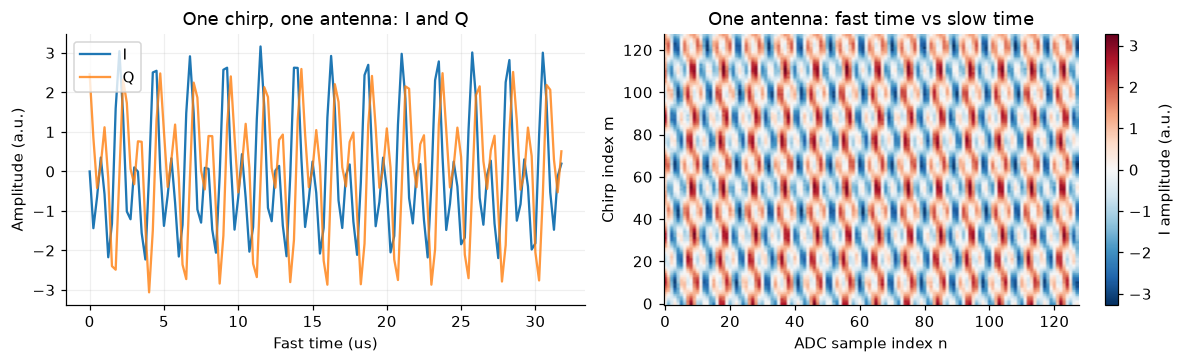

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
fast_us = np.arange(N) / fs * 1e6
axes[0].plot(fast_us, adc[0, 0].real, label="I")
axes[0].plot(fast_us, adc[0, 0].imag, label="Q", alpha=.8)
axes[0].set(xlabel="Fast time (us)", ylabel="Amplitude (a.u.)",
            title="One chirp, one antenna: I and Q")
axes[0].legend()
im = axes[1].imshow(adc[:, 0, :].real, origin="lower", aspect="auto", cmap="RdBu_r")
axes[1].set(xlabel="ADC sample index n", ylabel="Chirp index m",
            title="One antenna: fast time vs slow time")
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label="I amplitude (a.u.)")
finish("01_adc")

**Interpret the plots.** The left plot superimposes beat tones from several targets, which are hard to separate by eye.
The right plot still shows raw samples: its horizontal axis is not distance, and its vertical axis is not velocity. We construct physical coordinates next.

## 2. Range Spectrum

$$f_b \simeq \frac{2SR}{c},\qquad
R_k=\frac{c}{2S}\frac{k f_s}{N_R}.$$

`N_R` is the Range FFT length, while `N` is the number of actual ADC samples.
Multiply each chirp by a Hann window, then take the FFT along `axis=2`.
Average **power** over chirps and antennas to plot a single Range Spectrum.
Averaging complex values first can cause signals with different phases to cancel.

We follow the public dataset's positive-beat, unshifted `0 … fs` convention. For complex sampling, negative frequencies and their corresponding high positive frequencies are equivalent modulo $f_s$.
This range axis is not universal: real-valued ADC data, reversed I/Q, or different IF modes require the appropriate coordinate mapping.
Do not apply `rfft` to complex I/Q or automatically discard half of its FFT.
Usable range also depends on IF filtering and SNR; the plotted axis limit is not a guaranteed detection range.

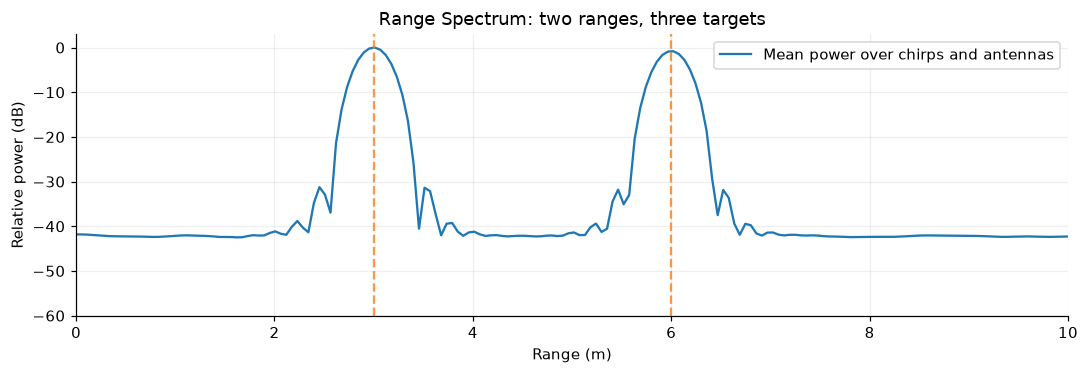

R [chirp, antenna, range] = (128, 8, 512)
FFT grid spacing = 0.056 m; physical resolution scale ≈ 0.223 m


In [5]:
NR = 512                         # 128 actual samples, zero-padded to 512
wr = np.hanning(N)
R = np.fft.fft(adc * wr[None, None, :], n=NR, axis=2) / wr.sum()
range_m = np.arange(NR) * fs / NR * C / (2*slope)
range_power = np.mean(np.abs(R)**2, axis=(0, 1))

plt.figure()
plt.plot(range_m, db_power(range_power), label="Mean power over chirps and antennas")
for r in np.unique(targets[:, 0]):
    plt.axvline(r, ls="--", color="tab:orange", alpha=.8)
plt.xlim(0, 10)
plt.ylim(-60, 3)
plt.xlabel("Range (m)")
plt.ylabel("Relative power (dB)")
plt.title("Range Spectrum: two ranges, three targets")
plt.legend()
finish("02_range_spectrum")
print("R [chirp, antenna, range] =", R.shape)
print(f"FFT grid spacing = {range_m[1]-range_m[0]:.3f} m; physical resolution scale ≈ {range_resolution:.3f} m")

**What to look for:** two groups of peaks near 3 m and 6 m. Two targets actually share the 6 m range; range alone cannot separate them.
Peak height depends on reflection amplitude, windowing, propagation loss, and other factors. It does not count targets.

**Class question:** if you change `NR` from 512 to 2048, will two closely spaced targets become physically easier to resolve?

**Core takeaway:** Hann weighting reduces sidelobes, while zero-padding makes the FFT grid denser. Neither should be confused with increasing physical observation bandwidth. The detailed comparison is in optional Appendix A.

## 3. Doppler Spectrum

A target can remain within the same range bin while its complex phase changes with motion:

$$\Delta\phi=\frac{4\pi v T_{\rm slow}}{\lambda},\qquad
f_D=\frac{2v}{\lambda},\qquad v=\frac{\lambda f_D}{2}.$$

$T_{\rm slow}$ is the time between **successive usable chirps from the same TX**, not the ADC sample interval or frame period.
Fix an antenna and range bin, then take the FFT across chirps. Use `fftshift` to place zero velocity at the center of the plot, and shift the frequency axis consistently.

**Predict first:** how many Doppler peaks should appear at 6 m? Where should the peak at 3 m appear?

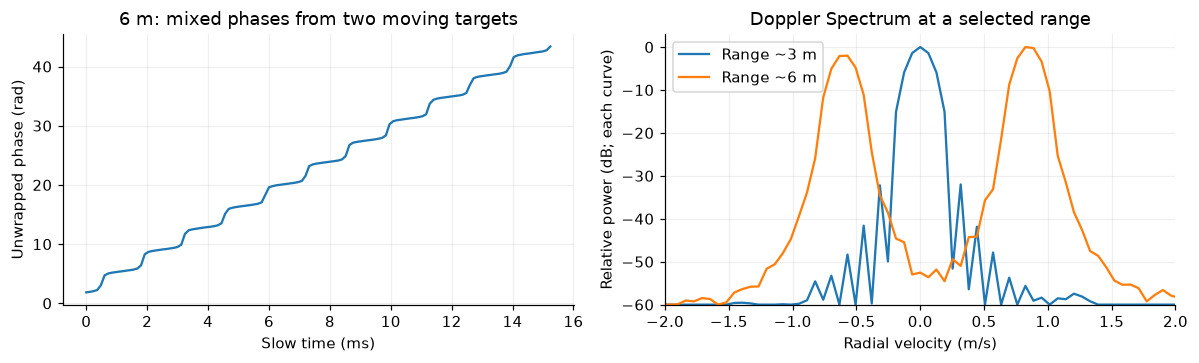

RD [doppler, antenna, range] = (256, 8, 512)


In [6]:
ND = 256
wd = np.hanning(M)
RD = np.fft.fftshift(
    np.fft.fft(R * wd[:, None, None], n=ND, axis=0), axes=0
) / wd.sum()
doppler_hz = np.fft.fftshift(np.fft.fftfreq(ND, d=Tslow))
velocity_m_s = wavelength * doppler_hz / 2
rd_power = np.mean(np.abs(RD)**2, axis=1)    # [doppler, range]
k3 = int(np.argmin(abs(range_m - 3.0)))
k6 = int(np.argmin(abs(range_m - 6.0)))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(np.arange(M)*Tslow*1e3, np.unwrap(np.angle(R[:, 0, k6])))
axes[0].set(xlabel="Slow time (ms)", ylabel="Unwrapped phase (rad)",
            title="6 m: mixed phases from two moving targets")
for k, label in [(k3, "Range ~3 m"), (k6, "Range ~6 m")]:
    axes[1].plot(velocity_m_s, db_power(rd_power[:, k]), label=label)
axes[1].set(xlim=(-2, 2), ylim=(-60, 3), xlabel="Radial velocity (m/s)",
            ylabel="Relative power (dB; each curve)", title="Doppler Spectrum at a selected range")
axes[1].legend()
finish("04_doppler_spectrum")
print("RD [doppler, antenna, range] =", RD.shape)

**What to look for:** a peak near 0 m/s at 3 m, and two peaks near −0.60 and +0.85 m/s at 6 m.
The combined phase on the left need not form a straight line; fitting a single phase slope to multiple targets is generally unreliable.
The two curves on the right are normalized separately to compare peak locations. Comparing their absolute strengths would require a common reference.

Next, plot the full **range–Doppler map**. Each pixel represents a range and radial-velocity cell, not a confirmed target.

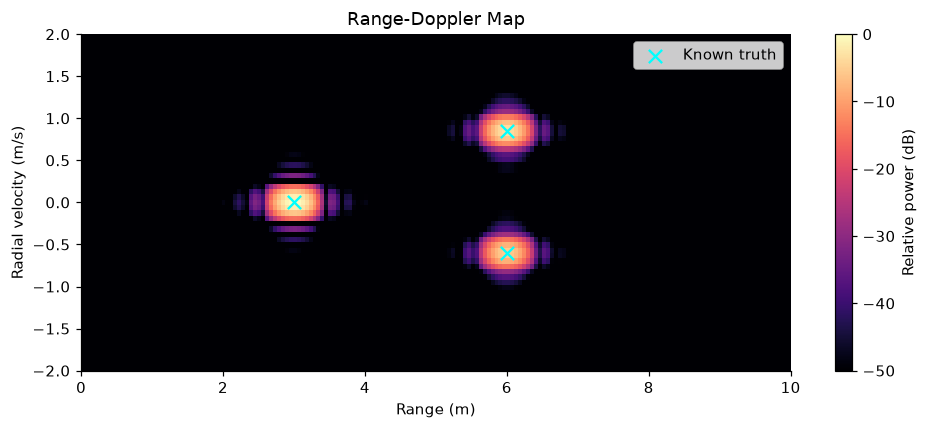

In [7]:
plt.figure(figsize=(9, 4))
heat = plt.pcolormesh(range_m, velocity_m_s, db_power(rd_power), shading="auto",
               cmap="magma", vmin=-50, vmax=0)
plt.scatter(targets[:, 0], targets[:, 1], marker="x", s=75, c="cyan", label="Known truth")
plt.xlim(0, 10)
plt.ylim(-2, 2)
plt.xlabel("Range (m)")
plt.ylabel("Radial velocity (m/s)")
plt.title("Range-Doppler Map")
plt.colorbar(heat, label="Relative power (dB)")
plt.legend()
plt.grid(False)
finish("05_range_doppler")

## 4. Angular Spectrum

First select a target's $(v,R)$ cell in the range–Doppler map.
Extract its complex values from all antennas as `z[a]`, then analyze the spatial spectrum:

$$z[a]\propto e^{j2\pi a(d/\lambda)\sin\theta},\qquad
q=\frac{d}{\lambda}\sin\theta,\qquad
\theta=\arcsin\left(q\frac{\lambda}{d}\right).$$

**Coordinate check:** FFT bins are evenly spaced in spatial frequency $q$, or $\sin\theta$, **not in angle $\theta$**.
Do not label the FFT axis using an arbitrary `linspace(-90, 90, NA)`.
Here $d=\lambda/2$, so $\theta=\arcsin(2q)$.

We compare two equivalent approaches:

1. **Angle FFT:** compute the spatial FFT of a uniform linear array and map its frequencies to angles using arcsin.
2. **Conventional beamforming / Bartlett:** compensate phase for each candidate angle, then sum coherently:
   $P(\theta)=|\mathbf a(\theta)^H\mathbf z|^2/A^2$.

Angle estimation requires phase. Feeding `abs(z)` to the FFT often produces a misleading broadside peak.
This section uses neither MUSIC nor other super-resolution methods or neural networks.

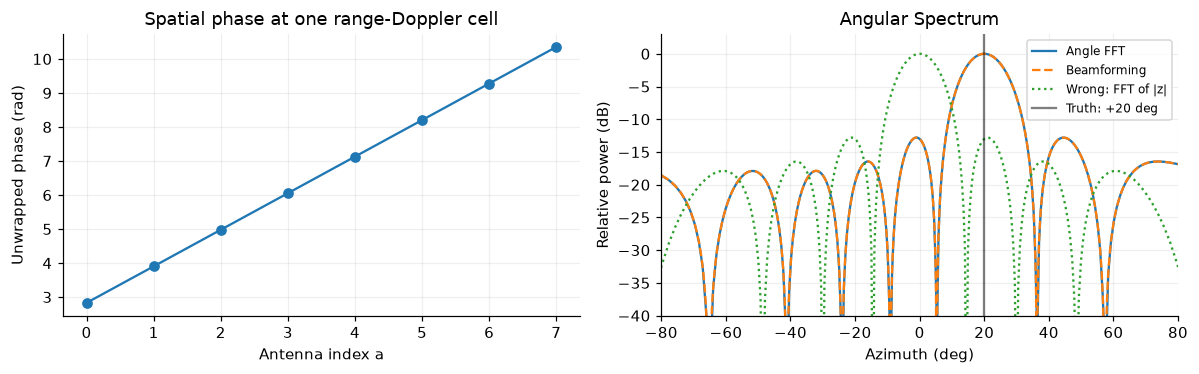

Selected cell: R=6.02 m, v=0.82 m/s
Angle FFT peak: 20.11 deg


In [8]:
NA = 256
angle_fft_deg = np.rad2deg(np.arcsin(
    np.fft.fftshift(np.fft.fftfreq(NA)) / d_lambda
))
scan_deg = np.linspace(-80, 80, 641)
steering = np.exp(1j * 2*np.pi * np.arange(A)[:, None] * d_lambda
                  * np.sin(np.deg2rad(scan_deg))[None, :])

# Find the strongest cell near 6 m at positive velocity; teaching selection, not CFAR.
gate = ((range_m[None, :] > 5.5) & (range_m[None, :] < 6.5)
        & (velocity_m_s[:, None] > .3) & (velocity_m_s[:, None] < 1.5))
di, ri = np.unravel_index(np.argmax(np.where(gate, rd_power, -np.inf)), rd_power.shape)
z = RD[di, :, ri]                       # Preserve complex antenna data
angle_power = abs(np.fft.fftshift(np.fft.fft(z, n=NA)))**2 / A**2
beam_power = abs(steering.conj().T @ z)**2 / A**2
bad_power = abs(np.fft.fftshift(np.fft.fft(abs(z), n=NA)))**2 / A**2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(np.arange(A), np.unwrap(np.angle(z)), "o-")
axes[0].set(xlabel="Antenna index a", ylabel="Unwrapped phase (rad)",
            title="Spatial phase at one range-Doppler cell")
reference = max(angle_power.max(), beam_power.max())
axes[1].plot(angle_fft_deg, db_power(angle_power, reference), label="Angle FFT")
axes[1].plot(scan_deg, db_power(beam_power, reference), "--", label="Beamforming")
axes[1].plot(angle_fft_deg, db_power(bad_power, reference), ":", label="Wrong: FFT of |z|")
axes[1].axvline(20, color="k", alpha=.5, label="Truth: +20 deg")
axes[1].set(xlim=(-80, 80), ylim=(-40, 3), xlabel="Azimuth (deg)",
            ylabel="Relative power (dB)", title="Angular Spectrum")
axes[1].legend(fontsize=8)
finish("07_angular_spectrum")
print(f"Selected cell: R={range_m[ri]:.2f} m, v={velocity_m_s[di]:.2f} m/s")
print(f"Angle FFT peak: {angle_fft_deg[np.argmax(angle_power)]:.2f} deg")

**What to look for:** both Angle FFT and beamforming peak near +20°.
The incorrect `FFT(abs(z))` discards directional phase information and shifts the peak toward 0°.
No spatial window is applied here, so both correct methods use the same rectangular aperture.

### 4.1 Check all three targets

Use the known scene only to check the simulated estimates. The next cell finds peaks near each
known range/velocity pair and estimates its angle from the complex antenna vector.
It is a numerical teaching check, not a general-purpose target detector.

In [9]:
# Use ground truth only for this teaching check, not for selecting real-data cells.
rows = []
for rt, vt, at, _ in targets:
    near = ((abs(range_m[None, :] - rt) < .3)
            & (abs(velocity_m_s[:, None] - vt) < .25))
    kd, kr = np.unravel_index(np.argmax(np.where(near, rd_power, -np.inf)), rd_power.shape)
    power = abs(steering.conj().T @ RD[kd, :, kr])**2
    estimated = (range_m[kr], velocity_m_s[kd], scan_deg[np.argmax(power)])
    assert abs(estimated[0]-rt) <= range_m[1]-range_m[0]
    assert abs(estimated[1]-vt) <= velocity_m_s[1]-velocity_m_s[0]
    assert abs(estimated[2]-at) < 1.0
    rows.append(f"| {rt:.2f}, {vt:+.2f}, {at:+.0f} | "
                f"{estimated[0]:.2f}, {estimated[1]:+.2f}, {estimated[2]:+.2f} |")
display(Markdown("| Truth R (m), v (m/s), θ (deg) | Estimated R, v, θ |\n"
                 "|---|---|\n" + "\n".join(rows)))
print("Known-target numerical checks passed (not an accuracy guarantee for arbitrary scenes).")

| Truth R (m), v (m/s), θ (deg) | Estimated R, v, θ |
|---|---|
| 3.00, +0.00, -25 | 3.01, +0.00, -25.00 |
| 6.00, +0.85, +20 | 6.02, +0.82, +20.00 |
| 6.00, -0.60, -15 | 6.02, -0.57, -15.00 |

Known-target numerical checks passed (not an accuracy guarantee for arbitrary scenes).


## Core checkpoint

Explain these three observations to a partner:

1. Three simulated targets produce two range peaks.
2. Doppler separates the targets at 6 m into approximately −0.60 and +0.85 m/s.
3. Keeping complex antenna phase recovers the selected target near +20°.

Now open [Notebook 2 — Real Radar Data](lab7_mmwave_real_data.ipynb) in its own kernel.
Its setup and calculations are independent of this notebook.
For homework, choose one optional experiment,
report prediction → result → explanation, and distinguish simulation truth from measured estimates.

## Optional appendices — after class

These demonstrations extend the core lesson. Run the core cells first, then work through the
appendices in order. No core cell depends on these optional extensions.

## Appendix A. Windowing and zero-padding

A sinusoid that falls between integer FFT bins produces spectral leakage.
A Hann window reduces sidelobes but widens the main lobe. Zero-padding samples the spectrum more densely without adding observation bandwidth or time.

The following example uses one noiseless target so that other targets cannot obscure the window's effect.
All curves are normalized by the window's coherent gain and plotted with a shared power reference.

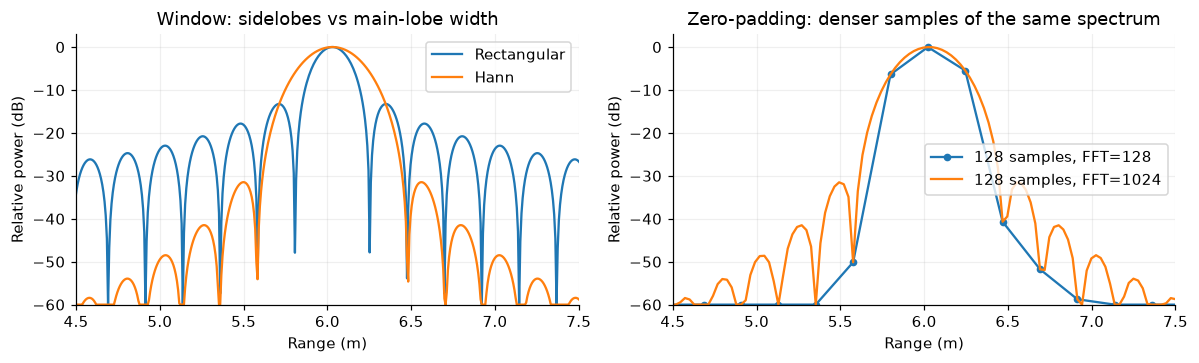

In [10]:
one = simulate(np.array([[6.03, 0.0, 0.0, 1.0]]), noise_sigma=0)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for window, label in [(np.ones(N), "Rectangular"), (np.hanning(N), "Hann")]:
    spectrum = np.fft.fft(one[0, 0]*window, n=4096) / window.sum()
    r_axis = np.arange(4096)*fs/4096*C/(2*slope)
    axes[0].plot(r_axis, db_power(abs(spectrum)**2, reference=1), label=label)
for length, style in [(N, "o-"), (1024, "-")]:
    spectrum = np.fft.fft(one[0, 0]*wr, n=length) / wr.sum()
    r_axis = np.arange(length)*fs/length*C/(2*slope)
    axes[1].plot(r_axis, db_power(abs(spectrum)**2, reference=1), style,
                 ms=4, label=f"{N} samples, FFT={length}")
for ax in axes:
    ax.set(xlim=(4.5, 7.5), ylim=(-60, 3), xlabel="Range (m)", ylabel="Relative power (dB)")
    ax.legend()
axes[0].set_title("Window: sidelobes vs main-lobe width")
axes[1].set_title("Zero-padding: denser samples of the same spectrum")
finish("03_window_padding")

**What to look for:** the Hann window lowers sidelobes and broadens the main lobe; zero-padding does not substantially change the main-lobe width.
The expression $\Delta R\approx c/(2B_{\rm observed})$ is a resolution scale for a rectangular observation window; Hann weighting broadens the main lobe further.
Here $B_{\rm observed}=S\,N/f_s$, which need not equal the bandwidth of the full hardware ramp.

## Appendix B. Static clutter removal

For each antenna and range bin, subtract the **complex mean across chirps**:

$$R_{\rm moving}[m,a,k]=R[m,a,k]-\frac{1}{M}\sum_{m'}R[m',a,k].$$

This suppresses components that do not change with slow time, often reducing reflections from walls and desks.
It also suppresses stationary objects of interest and can attenuate very slow motion. It is not a general-purpose denoising switch.
Remove the mean before applying the Doppler window, and compare before/after plots with the same dB reference.

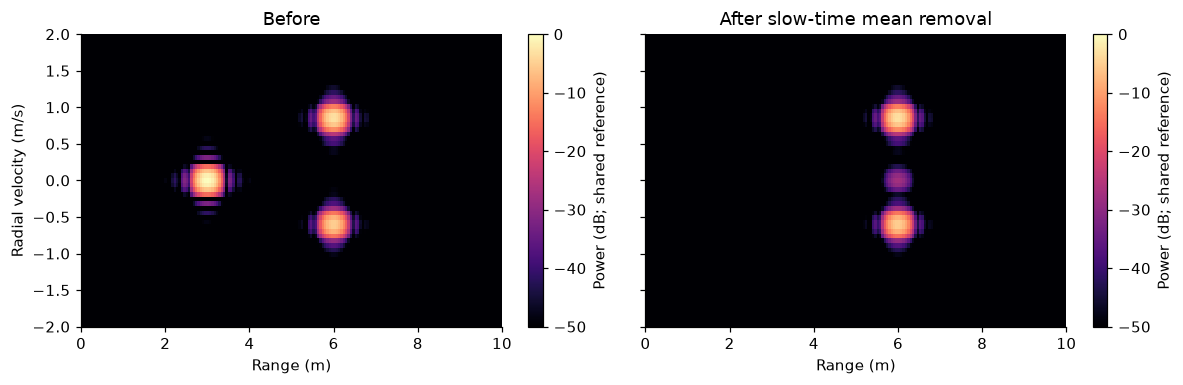

In [11]:
R_moving = R - R.mean(axis=0, keepdims=True)
RD_moving = np.fft.fftshift(
    np.fft.fft(R_moving * wd[:, None, None], n=ND, axis=0), axes=0
) / wd.sum()
moving_power = np.mean(abs(RD_moving)**2, axis=1)
shared_reference = rd_power.max()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, power, title in zip(axes, [rd_power, moving_power], ["Before", "After slow-time mean removal"]):
    im = ax.pcolormesh(range_m, velocity_m_s, db_power(power, shared_reference),
                      shading="auto", cmap="magma", vmin=-50, vmax=0)
    ax.set(xlim=(0, 10), ylim=(-2, 2), xlabel="Range (m)", title=title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, label="Power (dB; shared reference)")
axes[0].set_ylabel("Radial velocity (m/s)")
finish("06_clutter_removal")

**Stop and explain:** why did the stationary reflector at 3 m disappear? In an occupancy-sensing application, would that prove there is no stationary person in the room?

## Appendix C. Antenna count and aperture

**More antennas versus zero-padding.** Increasing the effective aperture narrows the angular main lobe.
Padding four antenna samples to 256 FFT points still provides only four physical spatial samples.
Near broadside, the angular-resolution scale of a rectangular ULA is approximately $\lambda/(A d)$ radians, and it worsens away from broadside.
The localization error of one high-SNR peak and the ability to resolve two targets are different metrics.

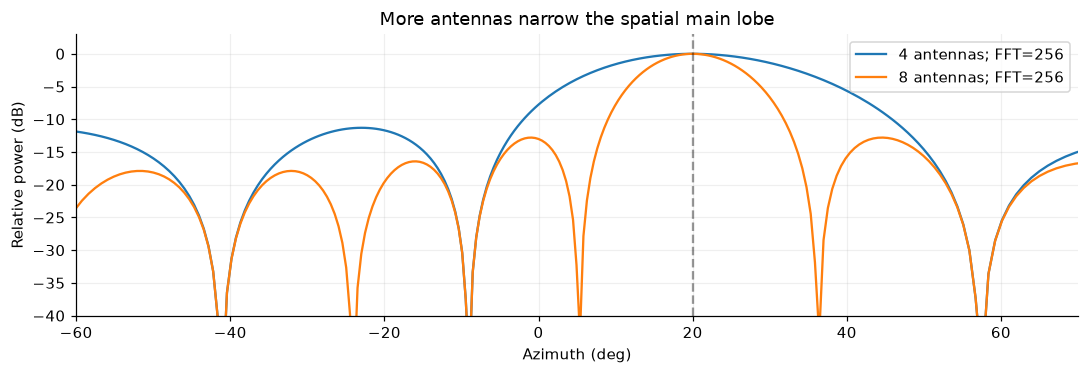

In [12]:
plt.figure()
for count in [4, 8]:
    spatial = np.exp(1j*2*np.pi*np.arange(count)*d_lambda*np.sin(np.deg2rad(20)))
    response = abs(np.fft.fftshift(np.fft.fft(spatial, n=NA)))**2 / count**2
    plt.plot(angle_fft_deg, db_power(response, reference=1), label=f"{count} antennas; FFT=256")
plt.axvline(20, color="k", ls="--", alpha=.4)
plt.xlim(-60, 70)
plt.ylim(-40, 3)
plt.xlabel("Azimuth (deg)")
plt.ylabel("Relative power (dB)")
plt.title("More antennas narrow the spatial main lobe")
plt.legend()
finish("08_array_aperture")

## Appendix D. Build a range–angle map

To display multiple directions, beamform each Doppler cell at each range, then **sum power across Doppler cells**.
This map retains stationary components.
Use a uniformly spaced angle grid with `pcolormesh` rather than incorrectly treating Angle FFT bins as uniform angles.
The result shows angular energy; it no longer labels velocity and is not directly a point cloud.

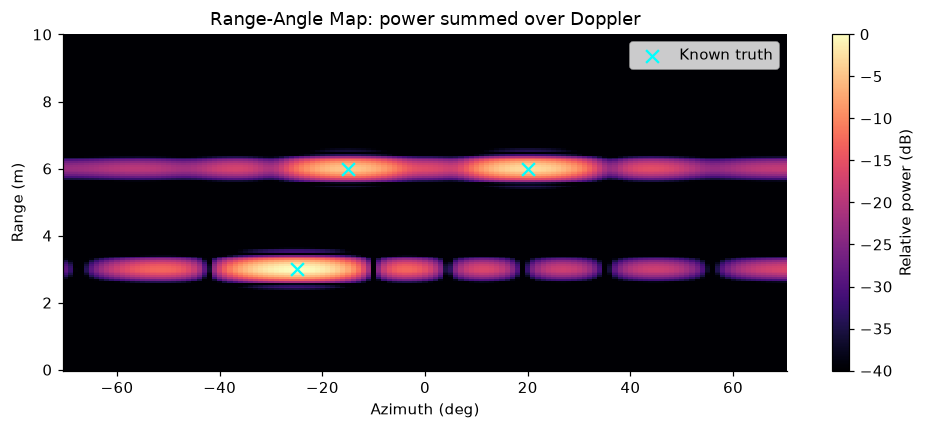

In [13]:
# Limit to 0–10 m to save memory; combine complex signals only across antennas.
range_view = range_m <= 10
scan_map_deg = np.linspace(-70, 70, 141)
steering_map = np.exp(1j*2*np.pi*np.arange(A)[:, None]*d_lambda
                      * np.sin(np.deg2rad(scan_map_deg))[None, :])
beam_cube = np.einsum("dar,at->dtr", RD[:, :, range_view], steering_map.conj(),
                      optimize=True) / A
ra_power = np.sum(abs(beam_cube)**2, axis=0)  # [angle, range]
plt.figure(figsize=(9, 4))
heat = plt.pcolormesh(scan_map_deg, range_m[range_view], db_power(ra_power).T,
               shading="auto", cmap="magma", vmin=-40, vmax=0)
plt.scatter(targets[:, 2], targets[:, 0], marker="x", s=70, c="cyan", label="Known truth")
plt.xlabel("Azimuth (deg)")
plt.ylabel("Range (m)")
plt.title("Range-Angle Map: power summed over Doppler")
plt.colorbar(heat, label="Relative power (dB)")
plt.legend()
plt.grid(False)
finish("09_range_angle")
del beam_cube

## Appendix E. Hands-on experiments

### Experiment A: same range and velocity, different angles

Place two targets at 6 m with velocity +0.85 m/s and angles −20° and +20°.
The range–Doppler map should show one moving region, but a sufficiently large aperture may still separate the two directions in the Angular Spectrum.
The code below runs independently and does not change the earlier three-target ground-truth checks.

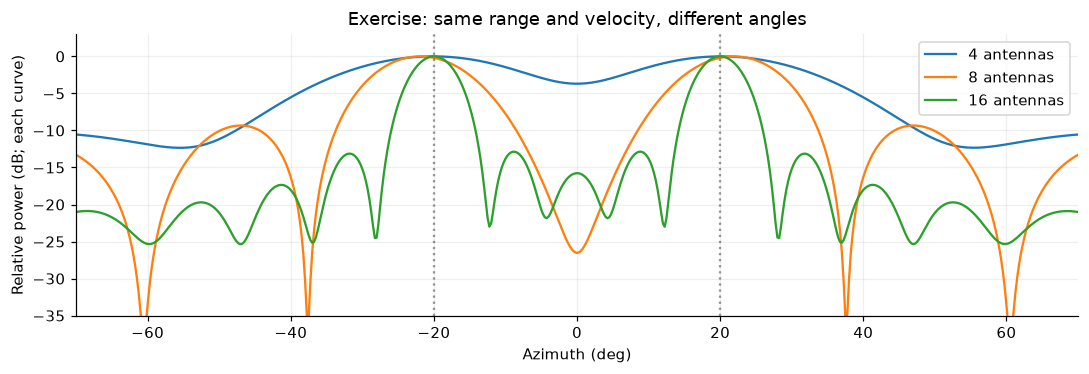

In [14]:
exercise_scene = np.array([[6.0, .85, -20.0, 1.0], [6.0, .85, 20.0, 1.0]])
plt.figure()
for antenna_count in [4, 8, 16]:
    ex_adc = simulate(exercise_scene, antennas=antenna_count, noise_sigma=.03)
    ex_r = np.fft.fft(ex_adc*wr[None, None, :], n=NR, axis=2) / wr.sum()
    ex_rd = np.fft.fftshift(np.fft.fft(ex_r*wd[:, None, None], n=ND, axis=0), axes=0) / wd.sum()
    kd = int(np.argmin(abs(velocity_m_s-.85)))
    kr = int(np.argmin(abs(range_m-6.0)))
    ex_steering = np.exp(1j*2*np.pi*np.arange(antenna_count)[:, None]*d_lambda
                         * np.sin(np.deg2rad(scan_deg))[None, :])
    ex_power = abs(ex_steering.conj().T @ ex_rd[kd, :, kr])**2 / antenna_count**2
    plt.plot(scan_deg, db_power(ex_power), label=f"{antenna_count} antennas")
for truth in [-20, 20]:
    plt.axvline(truth, color="k", ls=":", alpha=.4)
plt.xlim(-70, 70)
plt.ylim(-35, 3)
plt.xlabel("Azimuth (deg)")
plt.ylabel("Relative power (dB; each curve)")
plt.title("Exercise: same range and velocity, different angles")
plt.legend()
finish("15_exercise_same_range_velocity")

### Experiment B: chirp count and velocity resolution

Use two closely spaced velocity components, representing two scattering points at the same range.
Compare 32 and 128 chirps while keeping $T_{\rm slow}$ and the FFT length of 1024 fixed.
**Predict first:** both spectra use the same zero-padded FFT length. Which one will have narrower main lobes?

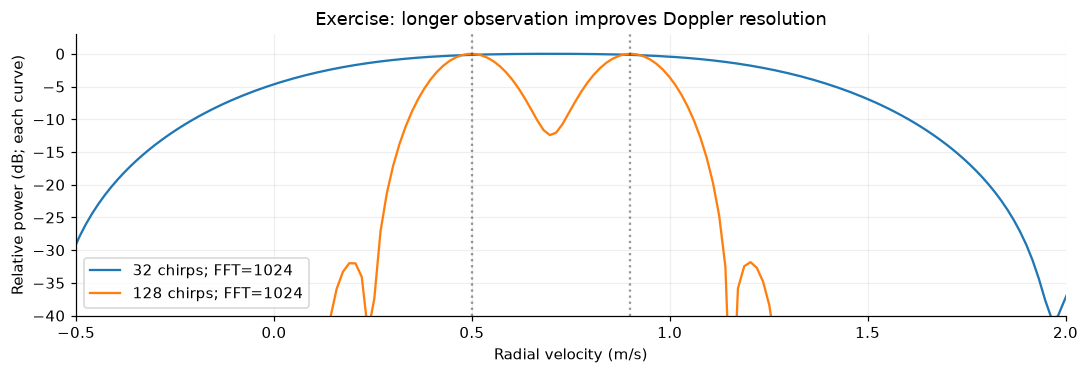

In [15]:
two_speeds = np.array([[6.0, .5, 0.0, 1.0], [6.0, .9, 0.0, 1.0]])
plt.figure()
for chirp_count in [32, 128]:
    ex_adc = simulate(two_speeds, chirps=chirp_count, antennas=1, noise_sigma=0)
    ex_r = np.fft.fft(ex_adc*wr[None, None, :], n=NR, axis=2)/wr.sum()
    ex_wd = np.hanning(chirp_count)
    ex_d = np.fft.fftshift(np.fft.fft(
        ex_r[:, 0, k6]*ex_wd, n=1024)) / ex_wd.sum()
    ex_v = np.fft.fftshift(np.fft.fftfreq(1024, Tslow))*wavelength/2
    plt.plot(ex_v, db_power(abs(ex_d)**2), label=f"{chirp_count} chirps; FFT=1024")
for speed in [.5, .9]:
    plt.axvline(speed, color="k", ls=":", alpha=.4)
plt.xlim(-.5, 2)
plt.ylim(-40, 3)
plt.xlabel("Radial velocity (m/s)")
plt.ylabel("Relative power (dB; each curve)")
plt.title("Exercise: longer observation improves Doppler resolution")
plt.legend()
finish("16_exercise_chirp_count")

### Experiment C: velocity aliasing

If the magnitude of the phase advance between adjacent chirps exceeds $\pi$, the samples cannot uniquely determine the true velocity.
The unambiguous interval is $[-\lambda/(4T_{\rm slow}),+\lambda/(4T_{\rm slow}))$.
Set a velocity outside that interval and compare its predicted aliased position with the FFT peak.
This illustrates the sampling model; real fast targets may also exhibit range migration, which this simplified model neglects.

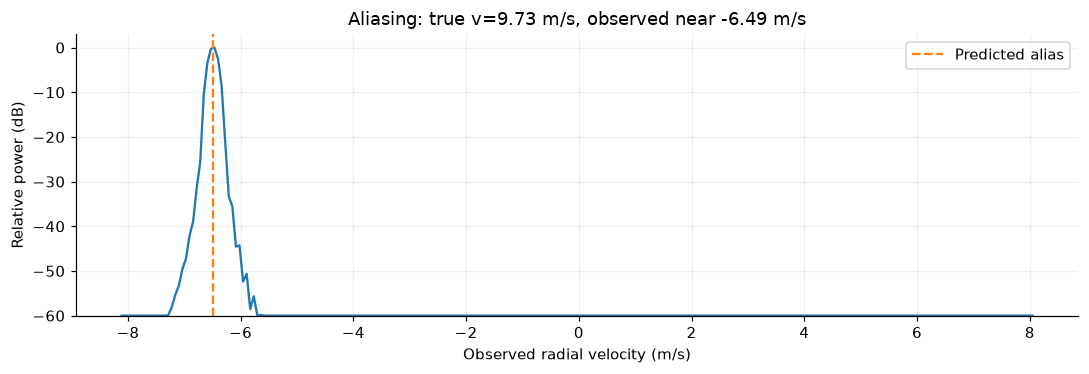

In [16]:
true_fast_v = 1.2*vmax
alias_v = (true_fast_v+vmax) % (2*vmax) - vmax
slow_signal = np.exp(1j*2*np.pi*(2*true_fast_v/wavelength)*np.arange(M)*Tslow)
aliased_spectrum = abs(np.fft.fftshift(np.fft.fft(slow_signal*wd, n=ND)))**2
measured_alias_v = velocity_m_s[np.argmax(aliased_spectrum)]
assert abs(measured_alias_v-alias_v) <= velocity_m_s[1]-velocity_m_s[0]
plt.figure()
plt.plot(velocity_m_s, db_power(aliased_spectrum))
plt.axvline(alias_v, ls="--", color="tab:orange", label="Predicted alias")
plt.xlabel("Observed radial velocity (m/s)")
plt.ylabel("Relative power (dB)")
plt.title(f"Aliasing: true v={true_fast_v:.2f} m/s, observed near {alias_v:.2f} m/s")
plt.ylim(-60, 3)
plt.legend()
finish("17_exercise_aliasing")

## Optional review

1. Why does increasing FFT length alone fail to improve physical range resolution?
2. What changes when you add antennas instead of zero-padding the antenna vector?
3. Why can slow-time mean removal hide a stationary person?
4. What limits the unambiguous velocity interval?

<details>
<summary>Instructor answer key</summary>

1. FFT padding changes grid density, not observed bandwidth.
2. Adding appropriately spaced antennas increases aperture; padding adds no spatial observations.
3. Mean removal suppresses stationary signals, including objects of interest.
4. The same-TX slow-time interval limits unambiguous velocity to ±λ/(4Tslow).

</details>

## References

* Real data, configuration, and license: [Gao et al.'s original repository](https://github.com/Xiangyu-Gao/mmWave-radar-signal-processing-and-microDoppler-classification);
  [local extraction and parameter notes](data/uw/README.md).
* Gao et al., *Experiments with mmWave Automotive Radar Test-bed*:
  [paper](https://arxiv.org/abs/1912.12566),
  [DOI](https://doi.org/10.1109/IEEECONF44664.2019.9048939).
* TI: [Intro to mmWave Sensing series](https://www.ti.com/video/series/mmwave-training-series.html),
  with modules on range, IF phase, velocity, and angle.
* TI: [Programming Chirp Parameters in TI Radar Devices, SWRA553A](https://www.ti.com/lit/an/swra553a/swra553a.pdf),
  for further details on chirp timing, bandwidth, and performance relationships.
* NumPy: [fft](https://numpy.org/doc/stable/reference/generated/numpy.fft.fft.html) and
  [fftfreq](https://numpy.org/doc/stable/reference/generated/numpy.fft.fftfreq.html).